## 1. Imports

In [1]:
import re, warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import svds
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
print("Libraries imported")

Libraries imported


## 2. Configuration
All tunable settings live in one place.

In [2]:
@dataclass
class Config:
    movies_path: str = "movies.csv"
    ratings_path: str = "ratings.csv"
    tags_path: Optional[str] = None
    out_dir: str = "outputs"

    # data filtering / split
    min_user_ratings: int = 5      # drop users with fewer ratings
    min_movie_ratings: int = 5     # drop movies with fewer ratings
    test_size: float = 0.2         # share of each user's ratings held out

    # model hyper-parameters
    knn_neighbors: int = 40
    knn_shrinkage: float = 10.0    # damps similarities built on few co-raters
    svd_factors: int = 20          # latent factors (tune: 10-100)
    bias_reg: float = 10.0         # damping for user/item biases
    hybrid_alpha: float = 0.7      # weight of collaborative score in the hybrid

    # evaluation
    top_k: int = 10
    relevant_threshold: float = 4.0  # test rating >= this counts as "liked"
    eval_users: int = 500

    seed: int = 42


cfg = Config()
cfg

Config(movies_path='movies.csv', ratings_path='ratings.csv', tags_path=None, out_dir='outputs', min_user_ratings=5, min_movie_ratings=5, test_size=0.2, knn_neighbors=40, knn_shrinkage=10.0, svd_factors=20, bias_reg=10.0, hybrid_alpha=0.7, top_k=10, relevant_threshold=4.0, eval_users=500, seed=42)

## 3. Load the data
Reads your CSV files; falls back to a synthetic demo dataset if they are missing.

In [3]:
def read_csv_safe(path: str) -> pd.DataFrame:
    try:
        return pd.read_csv(path)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1")


def load_data(cfg: Config):
    movies = read_csv_safe(cfg.movies_path)
    ratings = read_csv_safe(cfg.ratings_path)

    for name, df, cols in [
        ("movies", movies, {"movieId", "title", "genres"}),
        ("ratings", ratings, {"userId", "movieId", "rating"}),
    ]:
        missing = cols - set(df.columns)
        if missing:
            raise ValueError(f"{name} file is missing columns: {missing}")

    tags = None
    if cfg.tags_path and Path(cfg.tags_path).exists():
        tags = read_csv_safe(cfg.tags_path)
    return movies, ratings, tags


def make_demo_data(n_movies=1500, n_users=400, seed=0):
    """Small synthetic MovieLens-style data (only used when real files are absent)."""
    rng = np.random.RandomState(seed)
    G = ["Action", "Adventure", "Animation", "Children", "Comedy", "Crime",
         "Drama", "Fantasy", "Horror", "Romance", "Sci-Fi", "Thriller"]
    rows = []
    for i in range(1, n_movies + 1):
        gs = "|".join(rng.choice(G, rng.randint(1, 4), replace=False))
        name = {1: "Toy Story", 2: "Jumanji"}.get(i, f"Movie {i}")
        rows.append((i, f"{name} ({rng.randint(1970, 2015)})", gs))
    movies = pd.DataFrame(rows, columns=["movieId", "title", "genres"])
    gi = np.array([[g in m for g in G] for m in movies.genres.str.split("|")], float)
    uf = rng.randn(n_users, len(G))
    pop = rng.pareto(1.2, n_movies) + 1
    pop /= pop.sum()
    rt = []
    for u in range(1, n_users + 1):
        n = rng.randint(20, 150)
        items = rng.choice(n_movies, n, replace=False, p=pop)
        r = np.clip(np.round((3.5 + (gi[items] @ uf[u - 1] + rng.randn(n) * .7) * .5) * 2) / 2, 0.5, 5)
        rt += [(u, it + 1, x, 1150000000) for it, x in zip(items, r)]
    ratings = pd.DataFrame(rt, columns=["userId", "movieId", "rating", "timestamp"])
    return movies, ratings


if Path(cfg.movies_path).exists() and Path(cfg.ratings_path).exists():
    movies_raw, ratings_raw, tags = load_data(cfg)
    print("Loaded your files:", cfg.movies_path, "and", cfg.ratings_path)
else:
    movies_raw, ratings_raw = make_demo_data()
    tags = None
    print("movies.csv / ratings.csv not found -> using synthetic DEMO data")

print(f"movies_raw: {movies_raw.shape} | ratings_raw: {ratings_raw.shape}")

movies.csv / ratings.csv not found -> using synthetic DEMO data
movies_raw: (1500, 3) | ratings_raw: (33070, 4)


### 3.1 Preview the movies table

In [4]:
movies_raw.head(10)

,movieId,title,genres
0,1,Toy Story (1994),Drama
1,2,Jumanji (1978),Crime
2,3,Movie 3 (1999),Thriller|Adventure
3,4,Movie 4 (1998),Horror|Romance|Crime
4,5,Movie 5 (2012),Animation|Children|Fantasy
5,6,Movie 6 (1970),Action|Drama|Comedy
6,7,Movie 7 (2010),Adventure|Animation|Action
7,8,Movie 8 (1975),Animation|Thriller|Drama
8,9,Movie 9 (2009),Drama|Sci-Fi|Horror
9,10,Movie 10 (1973),Sci-Fi|Crime


### 3.2 Preview the ratings table

In [5]:
ratings_raw.head(10)

,userId,movieId,rating,timestamp
0,1,849,3.0,1150000000
1,1,860,2.5,1150000000
2,1,791,4.5,1150000000
3,1,1315,4.0,1150000000
4,1,1173,2.5,1150000000
5,1,1468,4.0,1150000000
6,1,976,3.0,1150000000
7,1,1193,4.0,1150000000
8,1,635,4.0,1150000000
9,1,148,4.5,1150000000


## 4. Exploratory Data Analysis

### 4.1 Dataset summary

In [6]:
n_u, n_m = ratings_raw.userId.nunique(), ratings_raw.movieId.nunique()
print(f"Movies: {len(movies_raw):,} | Ratings: {len(ratings_raw):,} | Users: {n_u:,} | Rated movies: {n_m:,}")
print(f"Rating-matrix sparsity: {1 - len(ratings_raw) / (n_u * n_m):.2%}")
print(f"Rating range: {ratings_raw.rating.min()} - {ratings_raw.rating.max()} | mean {ratings_raw.rating.mean():.2f}")
print("Missing values (movies): ", movies_raw.isna().sum().to_dict())
print("Missing values (ratings):", ratings_raw.isna().sum().to_dict())
print("Duplicate (user, movie) pairs:", ratings_raw.duplicated(["userId", "movieId"]).sum())

Movies: 1,500 | Ratings: 33,070 | Users: 400 | Rated movies: 1,499
Rating-matrix sparsity: 94.48%
Rating range: 0.5 - 5.0 | mean 3.49
Missing values (movies):  {'movieId': 0, 'title': 0, 'genres': 0}
Missing values (ratings): {'userId': 0, 'movieId': 0, 'rating': 0, 'timestamp': 0}
Duplicate (user, movie) pairs: 0


### 4.2 Rating statistics

In [7]:
ratings_raw.rating.describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
rating,33070.0,3.491352,0.771215,0.5,3.0,3.5,4.0,5.0


### 4.3 Rating distribution

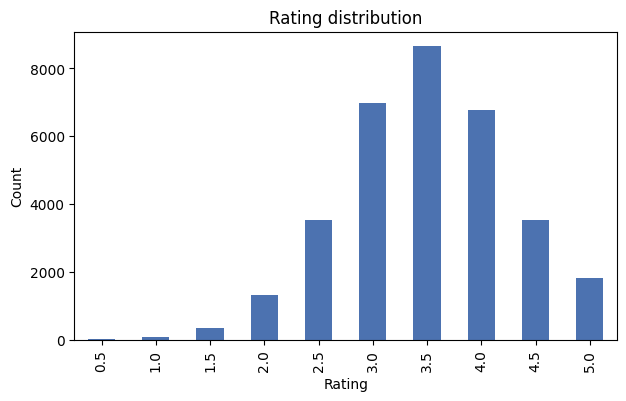

In [8]:
ax = ratings_raw.rating.value_counts().sort_index().plot.bar(figsize=(7, 4), color="#4C72B0")
ax.set(title="Rating distribution", xlabel="Rating", ylabel="Count")
plt.show()

### 4.4 Ratings per user and per movie (long tail)

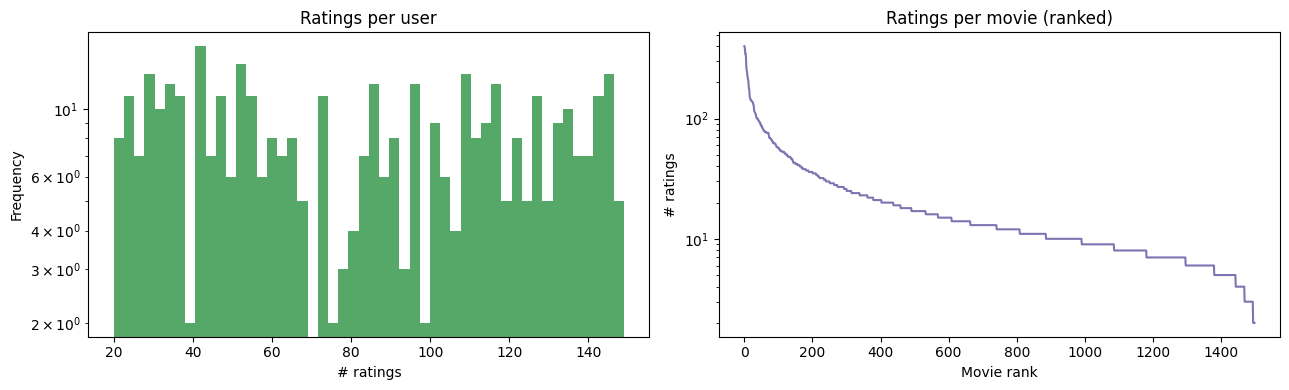

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ratings_raw.groupby("userId").size().plot.hist(bins=50, ax=ax[0], color="#55A868")
ax[0].set(title="Ratings per user", xlabel="# ratings", yscale="log")
ratings_raw.groupby("movieId").size().sort_values(ascending=False).reset_index(drop=True).plot(ax=ax[1], color="#8172B2")
ax[1].set(title="Ratings per movie (ranked)", xlabel="Movie rank", ylabel="# ratings", yscale="log")
plt.tight_layout(); plt.show()

### 4.5 Most common genres

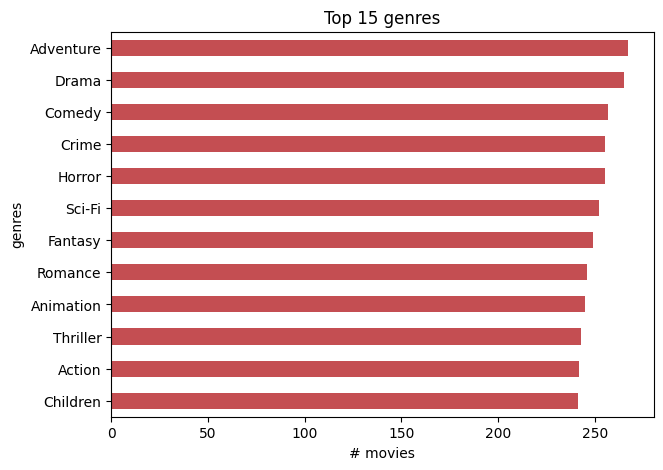

In [10]:
genres = (movies_raw.genres.fillna("").str.split("|").explode()
          .replace({"": np.nan, "(no genres listed)": np.nan}).dropna())
ax = genres.value_counts().head(15)[::-1].plot.barh(figsize=(7, 5), color="#C44E52")
ax.set(title="Top 15 genres", xlabel="# movies")
plt.show()

## 5. Preprocessing

### 5.1 Clean movies: extract year, genre list and the text used for content-based filtering

In [11]:
def _clean_tokens(text: str) -> str:
    return re.sub(r"[^a-z0-9 ]", " ", str(text).lower())


def preprocess_movies(movies: pd.DataFrame, tags: Optional[pd.DataFrame]) -> pd.DataFrame:
    """Extract year / genre list and build the text used by content-based filtering."""
    m = movies.copy()
    m["year"] = m["title"].str.extract(r"\((\d{4})\)\s*$")[0].astype(float)
    m["genres"] = m["genres"].fillna("").replace("(no genres listed)", "")
    m["genre_list"] = m["genres"].apply(lambda s: [g for g in s.split("|") if g])

    if tags is not None and {"movieId", "tag"} <= set(tags.columns):
        tag_text = (tags.dropna(subset=["tag"])
                    .assign(tag=lambda d: d.tag.map(_clean_tokens))
                    .groupby("movieId")["tag"].apply(" ".join))
        m["tag_text"] = m.movieId.map(tag_text).fillna("")
    else:
        m["tag_text"] = ""

    overview = m["overview"].fillna("").map(_clean_tokens) if "overview" in m.columns else ""

    def build_text(row_genres, year):
        toks = [g.replace("-", "").replace(" ", "").lower() for g in row_genres]
        if not np.isnan(year):
            toks.append(f"decade{int(year // 10 * 10)}")
        return " ".join(toks)

    m["content_text"] = [build_text(g, y) for g, y in zip(m.genre_list, m.year)]
    m["content_text"] = (m["content_text"] + " " + m["tag_text"] + " " + overview).str.strip()
    return m


movies_prep = preprocess_movies(movies_raw, tags)
movies_prep[["movieId", "title", "year", "genres", "content_text"]].head(8)

,movieId,title,year,genres,content_text
0,1,Toy Story (1994),1994.0,Drama,drama decade1990
1,2,Jumanji (1978),1978.0,Crime,crime decade1970
2,3,Movie 3 (1999),1999.0,Thriller|Adventure,thriller adventure decade1990
3,4,Movie 4 (1998),1998.0,Horror|Romance|Crime,horror romance crime decade1990
4,5,Movie 5 (2012),2012.0,Animation|Children|Fantasy,animation children fantasy decade2010
5,6,Movie 6 (1970),1970.0,Action|Drama|Comedy,action drama comedy decade1970
6,7,Movie 7 (2010),2010.0,Adventure|Animation|Action,adventure animation action decade2010
7,8,Movie 8 (1975),1975.0,Animation|Thriller|Drama,animation thriller drama decade1970


### 5.2 Clean ratings: drop sparse users/movies and duplicates

In [12]:
def filter_ratings(ratings: pd.DataFrame, movies: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    r = ratings[["userId", "movieId", "rating"]].dropna()
    r = r[r.movieId.isin(movies.movieId)]
    r = r.drop_duplicates(["userId", "movieId"], keep="last")
    # Iteratively drop sparse users/movies (each filter can affect the other)
    for _ in range(10):
        uc, mc = r.userId.value_counts(), r.movieId.value_counts()
        keep = (r.userId.isin(uc[uc >= cfg.min_user_ratings].index)
                & r.movieId.isin(mc[mc >= cfg.min_movie_ratings].index))
        if keep.all():
            break
        r = r[keep]
    return r.reset_index(drop=True)


ratings_clean = filter_ratings(ratings_raw, movies_prep, cfg)
print(f"Ratings before: {len(ratings_raw):,} -> after: {len(ratings_clean):,}")
print(f"Users: {ratings_clean.userId.nunique():,} | Movies: {ratings_clean.movieId.nunique():,}")

Ratings before: 33,070 -> after: 32,881
Users: 400 | Movies: 1,443


### 5.3 Per-user train/test split and sparse user × movie matrix

In [13]:
def per_user_split(ratings: pd.DataFrame, cfg: Config):
    """Hold out `test_size` of every user's ratings so each user is in both sets."""
    r = ratings.sample(frac=1, random_state=cfg.seed)
    rank = r.groupby("userId").cumcount()
    size = r.groupby("userId")["userId"].transform("size")
    is_test = rank < np.floor(size * cfg.test_size)
    return r[~is_test].reset_index(drop=True), r[is_test].reset_index(drop=True)


@dataclass
class Dataset:
    movies: pd.DataFrame          # one row per item, row position == item index
    train: pd.DataFrame
    test: pd.DataFrame
    user2idx: Dict[int, int]
    item2idx: Dict[int, int]
    R_train: sp.csr_matrix        # users x items

    @property
    def n_users(self):
        return self.R_train.shape[0]

    @property
    def n_items(self):
        return self.R_train.shape[1]

    def seen_items(self, u: int) -> np.ndarray:
        R = self.R_train
        return R.indices[R.indptr[u]:R.indptr[u + 1]]

    def seen_ratings(self, u: int) -> np.ndarray:
        R = self.R_train
        return R.data[R.indptr[u]:R.indptr[u + 1]]


def build_dataset(movies_raw, ratings_raw, tags, cfg: Config) -> Dataset:
    movies = preprocess_movies(movies_raw, tags)
    ratings = filter_ratings(ratings_raw, movies, cfg)

    movies = (movies[movies.movieId.isin(ratings.movieId.unique())]
              .sort_values("movieId").reset_index(drop=True))
    item2idx = {mid: i for i, mid in enumerate(movies.movieId)}
    user2idx = {uid: i for i, uid in enumerate(np.sort(ratings.userId.unique()))}

    ratings = ratings.assign(uidx=ratings.userId.map(user2idx).astype(int),
                             iidx=ratings.movieId.map(item2idx).astype(int))
    train, test = per_user_split(ratings, cfg)

    R = sp.csr_matrix((train.rating.values.astype(float),
                       (train.uidx.values, train.iidx.values)),
                      shape=(len(user2idx), len(item2idx)))

    cnt = np.bincount(train.iidx, minlength=len(movies))
    sm = np.bincount(train.iidx, weights=train.rating.values, minlength=len(movies))
    movies["n_ratings"] = cnt
    movies["avg_rating"] = np.divide(sm, cnt, out=np.zeros(len(cnt)), where=cnt > 0)

    print("\n" + "=" * 70 + "\nDATASET AFTER CLEANING / SPLIT\n" + "=" * 70)
    print(f"Users: {len(user2idx):,} | Movies: {len(item2idx):,} | "
          f"Train ratings: {len(train):,} | Test ratings: {len(test):,}")
    return Dataset(movies, train, test, user2idx, item2idx, R)


ds = build_dataset(movies_raw, ratings_raw, tags, cfg)
print("User x item training matrix:", ds.R_train.shape, "| non-zero entries:", ds.R_train.nnz)


DATASET AFTER CLEANING / SPLIT
Users: 400 | Movies: 1,443 | Train ratings: 26,467 | Test ratings: 6,414
User x item training matrix: (400, 1443) | non-zero entries: 26467


### 5.4 Look at the training and test sets

In [14]:
ds.train.head()

,userId,movieId,rating,uidx,iidx
0,298,110,4.0,297,106
1,334,916,4.0,333,877
2,298,477,4.0,297,461
3,374,1076,3.5,373,1030
4,34,394,4.5,33,383


In [15]:
ds.test.head()

,userId,movieId,rating,uidx,iidx
0,104,921,3.0,103,882
1,261,522,3.0,260,505
2,45,1276,0.5,44,1224
3,148,773,2.5,147,742
4,155,503,3.0,154,487


### 5.5 Movies table used by the models (with popularity statistics)

In [16]:
ds.movies[["title", "genres", "year", "n_ratings", "avg_rating"]].sort_values("n_ratings", ascending=False).head(10)

,title,genres,year,n_ratings,avg_rating
758,Movie 791 (1996),Children|Horror|Crime,1996.0,322,3.501553
1263,Movie 1315 (2013),Thriller,2013.0,315,3.458730
1411,Movie 1468 (2007),Romance,2007.0,303,3.526403
1104,Movie 1151 (1992),Crime|Action|Sci-Fi,1992.0,276,3.490942
487,Movie 503 (1993),Adventure|Horror|Crime,1993.0,265,3.520755
300,Movie 308 (1981),Sci-Fi|Animation,1981.0,251,3.517928
723,Movie 753 (1975),Sci-Fi|Comedy,1975.0,219,3.401826
174,Movie 178 (1983),Drama|Fantasy|Horror,1983.0,206,3.451456
644,Movie 669 (1995),Thriller,1995.0,190,3.481579
772,Movie 807 (1978),Adventure|Horror|Children,1978.0,186,3.502688


## 6. Helper functions

In [17]:
def zscore(x: np.ndarray) -> np.ndarray:
    s = x.std()
    return (x - x.mean()) / s if s > 1e-12 else np.zeros_like(x, dtype=float)


def top_n_indices(scores: np.ndarray, n: int, exclude: Optional[np.ndarray] = None):
    s = scores.astype(float).copy()
    if exclude is not None and len(exclude):
        s[exclude] = -np.inf
    n = max(1, min(n, int(np.isfinite(s).sum())))
    idx = np.argpartition(-s, n - 1)[:n]
    return idx[np.argsort(-s[idx])]


def find_movie(ds: Dataset, query: str) -> int:
    """Return the item index of the most-rated movie whose title contains `query`."""
    mask = ds.movies.title.str.contains(query, case=False, regex=False)
    if not mask.any():
        raise ValueError(f"No movie matching '{query}' in the filtered dataset.")
    return int(ds.movies[mask].sort_values("n_ratings", ascending=False).index[0])


print("Helpers ready")

Helpers ready


## 7. Models

### 7.1 Baselines: global mean, popularity and user/item bias model

In [18]:
class GlobalMean:
    """Predicts the global mean rating for everything (sanity-check baseline)."""

    def fit(self, ds: Dataset):
        self.mu = ds.train.rating.mean()
        return self

    def predict_items(self, u, items):
        return np.full(len(items), self.mu)


class PopularityRecommender:
    """Non-personalised: IMDB-style Bayesian weighted rating."""

    def fit(self, ds: Dataset):
        v = ds.movies.n_ratings.values.astype(float)
        R = ds.movies.avg_rating.values
        C = ds.train.rating.mean()
        m = np.percentile(v[v > 0], 80)
        self.scores = (v / (v + m)) * R + (m / (v + m)) * C
        return self

    def score_user(self, u):
        return self.scores


class BiasModel:
    """Baseline predictor: rating = global mean + user bias + item bias."""

    def __init__(self, reg: float = 10.0):
        self.reg = reg

    def fit(self, ds: Dataset):
        tr = ds.train
        u, i, r = tr.uidx.values, tr.iidx.values, tr.rating.values
        self.lo, self.hi = r.min(), r.max()
        self.mu = r.mean()
        ic = np.bincount(i, minlength=ds.n_items)
        self.bi = np.bincount(i, weights=r - self.mu, minlength=ds.n_items) / (ic + self.reg)
        resid = r - self.mu - self.bi[i]
        uc = np.bincount(u, minlength=ds.n_users)
        self.bu = np.bincount(u, weights=resid, minlength=ds.n_users) / (uc + self.reg)
        self._resid = r - self.mu - self.bi[i] - self.bu[u]  # reused by subclasses
        return self

    def _base(self, u, items):
        return self.mu + self.bu[u] + self.bi[items]

    def predict_items(self, u, items):
        return np.clip(self._base(u, items), self.lo, self.hi)

    def score_user(self, u):
        return self.predict_items(u, np.arange(len(self.bi)))


print("Baseline classes defined")

Baseline classes defined


### 7.2 Collaborative filtering – SVD matrix factorisation

In [19]:
class SVDRecommender(BiasModel):
    """Matrix factorisation: truncated SVD on the bias-removed rating matrix."""

    def __init__(self, n_factors: int = 20, reg: float = 10.0, seed: int = 42):
        super().__init__(reg)
        self.n_factors, self.seed = n_factors, seed

    def fit(self, ds: Dataset):
        super().fit(ds)
        tr = ds.train
        M = sp.csr_matrix((self._resid, (tr.uidx.values, tr.iidx.values)),
                          shape=(ds.n_users, ds.n_items))
        k = max(1, min(self.n_factors, min(M.shape) - 1))
        v0 = np.random.RandomState(self.seed).rand(min(M.shape))
        U, s, Vt = svds(M, k=k, v0=v0)
        self.P = U * s            # user factors  (n_users x k)
        self.Q = Vt.T             # item factors  (n_items x k)
        del self._resid
        return self

    def predict_items(self, u, items):
        return np.clip(self._base(u, items) + self.Q[items] @ self.P[u], self.lo, self.hi)


print("SVDRecommender defined")

SVDRecommender defined


### 7.3 Collaborative filtering – item-based kNN with cosine similarity

In [20]:
class ItemKNN(BiasModel):
    """
    Item-based collaborative filtering.
    Similarity = cosine between item columns of the (bias-removed) user-rating
    matrix, shrunk by number of co-raters. A rating is predicted from the
    user's own ratings of the k most similar items.
    """

    def __init__(self, k: int = 40, shrinkage: float = 10.0, reg: float = 10.0):
        super().__init__(reg)
        self.k, self.shrinkage = k, shrinkage

    def fit(self, ds: Dataset):
        super().fit(ds)
        tr = ds.train
        M = sp.csr_matrix((self._resid, (tr.uidx.values, tr.iidx.values)),
                          shape=(ds.n_users, ds.n_items))
        sim = cosine_similarity(M.T.tocsr(), dense_output=True).astype(np.float32)

        B = (ds.R_train > 0).astype(np.float32)
        co = (B.T @ B).toarray()                      # co-rater counts
        sim *= co / (co + self.shrinkage)
        np.fill_diagonal(sim, 0.0)
        self.sim = sim

        self.indptr, self.indices, self.data = M.indptr, M.indices, M.data
        del self._resid
        return self

    def predict_items(self, u, items):
        items = np.asarray(items)
        base = self._base(u, items)
        s, e = self.indptr[u], self.indptr[u + 1]
        rated, c = self.indices[s:e], self.data[s:e]
        if len(rated) == 0:
            return np.clip(base, self.lo, self.hi)

        S = self.sim[np.ix_(items, rated)]
        if S.shape[1] > self.k:                        # keep k nearest neighbours
            nn = np.argpartition(-S, self.k - 1, axis=1)[:, :self.k]
            rows = np.arange(S.shape[0])[:, None]
            S, C = S[rows, nn], c[nn]
        else:
            C = np.broadcast_to(c, S.shape)
        S = np.maximum(S, 0)                           # only positively similar items
        denom = S.sum(1)
        adj = np.divide((S * C).sum(1), denom, out=np.zeros_like(denom), where=denom > 1e-8)
        return np.clip(base + adj, self.lo, self.hi)

    def similar_items(self, i: int) -> np.ndarray:
        return self.sim[i]


print("ItemKNN defined")

ItemKNN defined


### 7.4 Content-based filtering – TF-IDF + cosine similarity

In [21]:
class ContentBasedRecommender:
    """TF-IDF over genre/decade/tag(/plot) tokens + cosine similarity."""

    def fit(self, ds: Dataset):
        self.ds = ds
        self.tfidf = TfidfVectorizer(token_pattern=r"\S+", sublinear_tf=True)
        self.X = self.tfidf.fit_transform(ds.movies["content_text"])  # rows are L2-normalised
        return self

    def item_similarity(self, i: int) -> np.ndarray:
        return cosine_similarity(self.X[i], self.X).ravel()

    def score_from_items(self, items: np.ndarray, ratings: np.ndarray) -> np.ndarray:
        """Build a user taste profile from rated items and score every movie."""
        if len(items) == 0:
            return np.zeros(self.X.shape[0])
        w = ratings - ratings.mean()          # liked items pull, disliked items push
        if np.allclose(w, 0):
            w = np.ones_like(ratings)
        profile = self.X[items].T.dot(w)
        norm = np.linalg.norm(profile)
        if norm < 1e-12:
            return np.zeros(self.X.shape[0])
        return self.X.dot(profile) / norm

    def score_user(self, u):
        return self.score_from_items(self.ds.seen_items(u), self.ds.seen_ratings(u))


print("ContentBasedRecommender defined")

ContentBasedRecommender defined


### 7.5 Hybrid recommender

In [22]:
class HybridRecommender:
    """alpha * z(collaborative) + (1 - alpha) * z(content-based)."""

    def __init__(self, cf, content, alpha: float = 0.7):
        self.cf, self.content, self.alpha = cf, content, alpha

    def score_user(self, u):
        return (self.alpha * zscore(self.cf.score_user(u))
                + (1 - self.alpha) * zscore(self.content.score_user(u)))


print("HybridRecommender defined")

HybridRecommender defined


## 8. Train all models

In [23]:
np.random.seed(cfg.seed)

glob    = GlobalMean().fit(ds);                                          print("Global-mean baseline   done")
pop     = PopularityRecommender().fit(ds);                               print("Popularity             done")
bias    = BiasModel(cfg.bias_reg).fit(ds);                               print("Bias baseline          done")
content = ContentBasedRecommender().fit(ds);                             print("Content-based (TF-IDF) done")
knn     = ItemKNN(cfg.knn_neighbors, cfg.knn_shrinkage, cfg.bias_reg).fit(ds);  print("Item-kNN CF            done")
svd     = SVDRecommender(cfg.svd_factors, cfg.bias_reg, cfg.seed).fit(ds);      print("SVD CF                 done")
hybrid  = HybridRecommender(svd, content, cfg.hybrid_alpha);             print(f"Hybrid (CF x {cfg.hybrid_alpha} + content x {1 - cfg.hybrid_alpha:.1f}) ready")

models = {"Global mean": glob, "Popularity": pop, "Bias baseline": bias,
          "Content-based": content, "Item-kNN CF": knn, "SVD CF": svd, "Hybrid": hybrid}

Global-mean baseline   done
Popularity             done
Bias baseline          done
Content-based (TF-IDF) done
Item-kNN CF            done
SVD CF                 done
Hybrid (CF x 0.7 + content x 0.3) ready


### 8.1 Inspect the learned structures

In [24]:
print("TF-IDF content matrix :", content.X.shape, "(movies x vocabulary)")
print("Vocabulary            :", list(content.tfidf.vocabulary_)[:15], "...")
print("Item-item similarity  :", knn.sim.shape)
print("SVD user factors      :", svd.P.shape, "| item factors:", svd.Q.shape)

TF-IDF content matrix : (1443, 17) (movies x vocabulary)
Vocabulary            : ['drama', 'decade1990', 'crime', 'decade1970', 'thriller', 'adventure', 'horror', 'romance', 'animation', 'children', 'fantasy', 'decade2010', 'action', 'comedy', 'scifi'] ...
Item-item similarity  : (1443, 1443)
SVD user factors      : (400, 20) | item factors: (1443, 20)


## 9. Evaluation

### 9.1 Rating-prediction error on held-out ratings (lower is better)

In [25]:
def rating_metrics(model, ds: Dataset) -> Dict[str, float]:
    preds, truth = [], []
    for u, g in ds.test.groupby("uidx"):
        preds.append(model.predict_items(u, g.iidx.values))
        truth.append(g.rating.values)
    p, t = np.concatenate(preds), np.concatenate(truth)
    return {"RMSE": float(np.sqrt(np.mean((p - t) ** 2))), "MAE": float(np.mean(np.abs(p - t)))}


rating_df = pd.DataFrame({n: rating_metrics(m, ds) for n, m in models.items()
                          if hasattr(m, "predict_items")}).T.round(4)
rating_df

,RMSE,MAE
Global mean,0.7774,0.6039
Bias baseline,0.7361,0.5919
Item-kNN CF,0.6655,0.5290
SVD CF,0.7019,0.5626


### 9.2 Top-N ranking quality (higher is better)
A test rating ≥ 4.0 counts as a movie the user liked.

In [26]:
def ranking_metrics(model, ds: Dataset, cfg: Config) -> Dict[str, float]:
    k = cfg.top_k
    relevant = (ds.test[ds.test.rating >= cfg.relevant_threshold]
                .groupby("uidx").iidx.apply(set).to_dict())
    users = np.array(sorted(relevant))
    rng = np.random.RandomState(cfg.seed)
    if len(users) > cfg.eval_users:
        users = rng.choice(users, cfg.eval_users, replace=False)

    disc = 1.0 / np.log2(np.arange(2, k + 2))
    P, R, N, H, recommended = [], [], [], [], set()
    for u in users:
        rel = relevant[u]
        top = top_n_indices(model.score_user(u), k, exclude=ds.seen_items(u))
        hits = np.array([i in rel for i in top], dtype=float)
        idcg = disc[:min(len(rel), k)].sum()
        P.append(hits.sum() / k)
        R.append(hits.sum() / len(rel))
        N.append((hits * disc[:len(hits)]).sum() / idcg)
        H.append(float(hits.any()))
        recommended.update(top.tolist())
    return {f"Precision@{k}": np.mean(P), f"Recall@{k}": np.mean(R),
            f"NDCG@{k}": np.mean(N), f"HitRate@{k}": np.mean(H),
            "Coverage": len(recommended) / ds.n_items}


rank_df = pd.DataFrame({n: ranking_metrics(m, ds, cfg) for n, m in models.items()
                        if hasattr(m, "score_user")}).T.round(4)
rank_df

,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage
Popularity,0.0032,0.0042,0.0036,0.0317,0.0097
Bias baseline,0.0032,0.0042,0.0033,0.0317,0.0090
Content-based,0.0106,0.0260,0.0152,0.1032,0.8468
Item-kNN CF,0.0079,0.0125,0.0088,0.0767,0.5599
SVD CF,0.0238,0.0348,0.0347,0.2090,0.1130
Hybrid,0.0259,0.0415,0.0401,0.2116,0.1705


### 9.3 Compare models visually

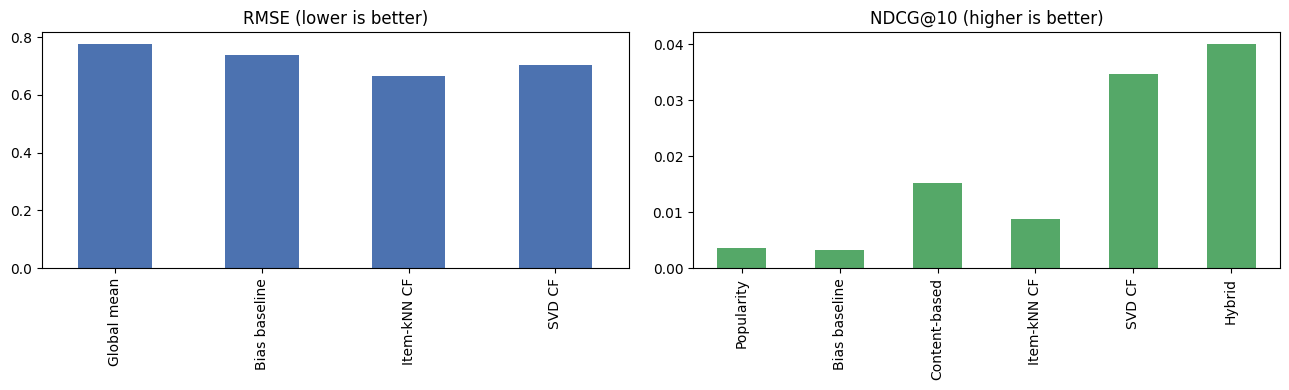

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rating_df["RMSE"].plot.bar(ax=ax[0], color="#4C72B0", title="RMSE (lower is better)")
rank_df[f"NDCG@{cfg.top_k}"].plot.bar(ax=ax[1], color="#55A868", title=f"NDCG@{cfg.top_k} (higher is better)")
plt.tight_layout(); plt.show()

## 10. Generating recommendations

In [28]:
def user_history(ds: Dataset, user_id: int, n: int = 8) -> pd.DataFrame:
    u = ds.user2idx[user_id]
    items, r = ds.seen_items(u), ds.seen_ratings(u)
    order = np.argsort(-r)[:n]
    return pd.DataFrame({"title": ds.movies.title.values[items[order]],
                         "genres": ds.movies.genres.values[items[order]],
                         "your_rating": r[order]})


def recommend_for_user(model, ds: Dataset, user_id: int, n: int = 10,
                       knn: Optional[ItemKNN] = None) -> pd.DataFrame:
    """Top-n unseen movies for an existing user (optionally with an explanation)."""
    u = ds.user2idx[user_id]
    scores = model.score_user(u)
    top = top_n_indices(scores, n, exclude=ds.seen_items(u))
    out = pd.DataFrame({"title": ds.movies.title.values[top],
                        "genres": ds.movies.genres.values[top],
                        "score": np.round(scores[top], 3)})
    if knn is not None:  # "Because you liked ..."
        seen, r = ds.seen_items(u), ds.seen_ratings(u)
        liked = seen[r >= 4.0]
        if len(liked):
            out["because_you_liked"] = [
                ds.movies.title.values[liked[np.argmax(knn.sim[i, liked])]] for i in top]
    return out


# pick the most active user (or set your own userId here)
user_id = int(ds.train.groupby("userId").size().idxmax())
print("Selected user:", user_id)

Selected user: 152


### 10.1 What this user liked in the past

In [29]:
user_history(ds, user_id, n=8)

,title,genres,your_rating
0,Movie 74 (1994),Fantasy|Comedy|Drama,5.0
1,Movie 187 (2003),Drama|Fantasy,5.0
2,Movie 537 (1977),Fantasy|Drama|Sci-Fi,5.0
3,Movie 1078 (1994),Fantasy|Adventure|Animation,5.0
4,Movie 1005 (2009),Adventure|Children|Fantasy,5.0
5,Movie 219 (1990),Comedy|Fantasy|Crime,4.5
6,Movie 237 (2002),Horror|Romance|Adventure,4.5
7,Movie 170 (2006),Drama|Crime,4.5


### 10.2 Hybrid recommendations

In [30]:
recommend_for_user(hybrid, ds, user_id, cfg.top_k)

,title,genres,score
0,Movie 1158 (2010),Adventure|Drama|Animation,3.620
1,Movie 427 (2014),Fantasy|Adventure,3.038
2,Movie 21 (1971),Fantasy|Adventure,2.399
3,Movie 988 (1993),Adventure|Fantasy,2.337
4,Movie 1004 (2007),Adventure|Fantasy,2.322
5,Movie 681 (2005),Adventure|Children,2.249
6,Movie 819 (1992),Drama|Romance,2.186
7,Movie 173 (1974),Adventure|Fantasy,2.085
8,Movie 708 (2003),Adventure|Romance|Fantasy,1.983
9,Movie 145 (1977),Animation|Horror|Adventure,1.925


### 10.3 SVD collaborative-filtering recommendations

In [31]:
recommend_for_user(svd, ds, user_id, cfg.top_k)

,title,genres,score
0,Movie 1158 (2010),Adventure|Drama|Animation,4.182
1,Movie 427 (2014),Fantasy|Adventure,4.044
2,Movie 819 (1992),Drama|Romance,3.999
3,Movie 590 (1987),Sci-Fi|Animation|Drama,3.941
4,Movie 749 (1986),Action|Drama,3.932
5,Movie 21 (1971),Fantasy|Adventure,3.932
6,Movie 681 (2005),Adventure|Children,3.929
7,Movie 1279 (1999),Horror|Crime,3.920
8,Movie 195 (2003),Children|Adventure|Romance,3.893
9,Movie 1004 (2007),Adventure|Fantasy,3.886


### 10.4 Item-kNN recommendations with explanations

In [32]:
recommend_for_user(knn, ds, user_id, cfg.top_k, knn=knn)

,title,genres,score,because_you_liked
0,Movie 1382 (1975),Adventure|Children|Romance,4.253,Movie 1078 (1994)
1,Movie 590 (1987),Sci-Fi|Animation|Drama,4.148,Movie 446 (1991)
2,Movie 427 (2014),Fantasy|Adventure,4.141,Movie 110 (1990)
3,Movie 15 (2006),Fantasy,4.111,Movie 537 (1977)
4,Movie 764 (1985),Fantasy,4.110,Movie 74 (1994)
5,Movie 642 (2006),Fantasy,4.098,Movie 187 (2003)
6,Movie 1047 (1988),Fantasy|Action,4.096,Movie 26 (1993)
7,Movie 853 (1980),Adventure|Comedy|Fantasy,4.084,Movie 503 (1993)
8,Movie 1079 (1970),Fantasy|Children|Drama,4.054,Movie 187 (2003)
9,Movie 909 (1974),Adventure,4.049,Movie 1078 (1994)


### 10.5 Content-based recommendations

In [33]:
recommend_for_user(content, ds, user_id, cfg.top_k)

,title,genres,score
0,Movie 1305 (1991),Adventure|Fantasy,0.612
1,Movie 275 (1991),Fantasy|Adventure,0.612
2,Movie 988 (1993),Adventure|Fantasy,0.612
3,Movie 1065 (2012),Fantasy|Adventure|Drama,0.611
4,Movie 1373 (1998),Fantasy|Horror|Adventure,0.603
5,Movie 959 (1990),Horror|Fantasy|Adventure,0.603
6,Movie 1004 (2007),Adventure|Fantasy,0.600
7,Movie 583 (2000),Fantasy|Adventure,0.600
8,Movie 1481 (2009),Fantasy|Adventure,0.600
9,Movie 176 (1997),Children|Adventure|Fantasy,0.562


### 10.6 Popularity baseline (same list for everyone)

In [34]:
recommend_for_user(pop, ds, user_id, cfg.top_k)

,title,genres,score
0,Movie 819 (1992),Drama|Romance,3.746
1,Movie 145 (1977),Animation|Horror|Adventure,3.729
2,Movie 681 (2005),Adventure|Children,3.708
3,Movie 1279 (1999),Horror|Crime,3.702
4,Movie 1371 (1992),Action|Crime,3.702
5,Movie 590 (1987),Sci-Fi|Animation|Drama,3.698
6,Movie 988 (1993),Adventure|Fantasy,3.687
7,Movie 353 (2003),Children,3.677
8,Movie 195 (2003),Children|Adventure|Romance,3.677
9,Movie 434 (1978),Action|Animation|Romance,3.675


## 11. Similar movies (rating-matrix cosine + genre/tag cosine)

In [35]:
def similar_movies(ds: Dataset, content: ContentBasedRecommender, knn: ItemKNN,
                   query: str, n: int = 10, w_cf: float = 0.5) -> pd.DataFrame:
    """Movies similar to `query`, blending rating-based and genre/tag-based cosine similarity."""
    i = find_movie(ds, query)
    cb = content.item_similarity(i)
    cf = np.maximum(knn.similar_items(i), 0)
    blend = w_cf * zscore(cf) + (1 - w_cf) * zscore(cb)
    blend[i] = -np.inf
    top = top_n_indices(blend, n)
    print(f"\nMovies similar to: {ds.movies.title.values[i]}")
    return pd.DataFrame({"title": ds.movies.title.values[top],
                         "genres": ds.movies.genres.values[top],
                         "content_sim": np.round(cb[top], 3),
                         "rating_sim": np.round(cf[top], 3)})


similar_movies(ds, content, knn, "Toy Story", n=10)


Movies similar to: Toy Story (1994)


,title,genres,content_sim,rating_sim
0,Movie 90 (1992),Thriller,0.438,0.042
1,Movie 731 (1999),Comedy|Romance|Fantasy,0.304,0.044
2,Movie 1315 (2013),Thriller,0.000,0.048
3,Movie 531 (2009),Horror|Children|Drama,0.373,0.038
4,Movie 517 (1989),Thriller|Adventure|Romance,0.000,0.045
5,Movie 1082 (1996),Drama|Fantasy|Horror,0.682,0.029
6,Movie 1309 (2001),Drama,0.544,0.031
7,Movie 1416 (2004),Animation|Thriller|Action,0.000,0.039
8,Movie 890 (1995),Drama,1.000,0.016
9,Movie 520 (2004),Action|Fantasy,0.000,0.036


## 12. Cold-start: a brand-new user with no history

In [36]:
def recommend_for_new_user(ds: Dataset, content: ContentBasedRecommender,
                           liked_titles: List[str], n: int = 10,
                           pop: Optional[PopularityRecommender] = None) -> pd.DataFrame:
    """Cold start: recommend from a handful of titles the new user says they like."""
    items = []
    for t in liked_titles:
        try:
            items.append(find_movie(ds, t))
        except ValueError as e:
            print(e)
    if not items:                                   # nothing usable -> popularity fallback
        scores = pop.scores if pop is not None else ds.movies.avg_rating.values
        top = top_n_indices(scores, n)
    else:
        items = np.array(items)
        scores = content.score_from_items(items, np.full(len(items), 5.0))
        top = top_n_indices(scores, n, exclude=items)
    return pd.DataFrame({"title": ds.movies.title.values[top],
                         "genres": ds.movies.genres.values[top]})


recommend_for_new_user(ds, content, ["Toy Story", "Jumanji"], n=10, pop=pop)

,title,genres
0,Movie 42 (1976),Crime|Adventure|Drama
1,Movie 1063 (1990),Drama|Sci-Fi|Crime
2,Movie 199 (1990),Drama|Horror|Crime
3,Movie 373 (1970),Fantasy|Crime|Drama
4,Movie 107 (1990),Crime|Thriller|Drama
5,Movie 1163 (1974),Drama|Crime|Romance
6,Movie 142 (1978),Crime|Drama|Action
7,Movie 954 (1974),Action|Crime|Drama
8,Movie 812 (1993),Crime
9,Movie 279 (1993),Crime


## 13. Save the trained models

In [37]:
out_dir = Path(cfg.out_dir); out_dir.mkdir(exist_ok=True)
joblib.dump({"config": cfg, "dataset": ds, "popularity": pop, "content": content,
             "knn": knn, "svd": svd, "hybrid": hybrid}, out_dir / "recommender_artifacts.joblib", compress=3)
rating_df.to_csv(out_dir / "metrics_rating_prediction.csv")
rank_df.to_csv(out_dir / "metrics_ranking.csv")
print("Saved:", sorted(p.name for p in out_dir.iterdir()))

Saved: ['metrics_ranking.csv', 'metrics_rating_prediction.csv', 'recommender_artifacts.joblib']
